# TP DES & AES — Parties 4 & 5 : performances et comparaison avec une bibliothèque

On réutilise l'implémentation du notebook `02_DES.ipynb`. La bibliothèque de référence est **PyCryptodome** (`Crypto.Cipher.DES`, implémentée en C).

> Installation si besoin : `pip install pycryptodome`

⚠️ La mesure complète jusqu'à $2^{26}$ octets prend environ 8 minutes avec notre implémentation en Python pur. On peut réduire `MAX_EXP` pour tester plus vite.

In [1]:
%run ./02_DES.ipynb

K+ (PC-1)   : 1111000 0110011 0010101 0101111 0101010 1011001 1001111 0001111
K1 (PC-2)   : 000110 110000 001011 101111 111111 000111 000001 110010
IP(M)       : 11001100 00000000 11001100 11111111 11110000 10101010 11110000 10101010
E(R0)       : 011110 100001 010101 010101 011110 100001 010101 010101
E(R0)^K1    : 011000 010001 011110 111010 100001 100110 010100 100111
S-box       : 0101 1100 1000 0010 1011 0101 1001 0111
f(R0,K1)    : 0010 0011 0100 1010 1010 1001 1011 1011

chiffré (version rapide)  : 85E813540F0AB405
chiffré (version simple)  : 85E813540F0AB405
déchiffré                 : 0123456789ABCDEF
226dfab1f7a734470847d2f299d2879f04d5aa1fed53b03e44c642e93128e87441282b5087761b61
b'Data Encryption Standard - TP 5IF'


In [2]:
import os, time
import pandas as pd
import matplotlib.pyplot as plt
from Crypto.Cipher import DES

MAX_EXP = 26
key = os.urandom(8)

## Mesures

Pour chaque taille $2^{10}$ … $2^{26}$ octets, on génère un message aléatoire, on le chiffre (mode ECB, sans padding car les tailles sont des multiples de 8) avec notre implémentation et avec PyCryptodome, et on mesure le temps avec `time.perf_counter()`.

Pour les petites tailles, le temps de la bibliothèque est très court (quelques µs), on répète donc la mesure plusieurs fois et on garde la moyenne.

On vérifie au passage que les deux chiffrés sont identiques.

In [3]:
rows = []
for e in range(10, MAX_EXP + 1):
    size = 2 ** e
    data = os.urandom(size)

    t0 = time.perf_counter()
    c_ours = des_encrypt(data, key, pad=False)
    t_ours = time.perf_counter() - t0

    reps = max(1, 2 ** (20 - e))   # plus de répétitions pour les petites tailles
    t0 = time.perf_counter()
    for _ in range(reps):
        c_lib = DES.new(key, DES.MODE_ECB).encrypt(data)
    t_lib = (time.perf_counter() - t0) / reps

    rows.append({"taille (o)": size, "blocs": size // 8,
                 "t_nous (s)": t_ours, "t_lib (s)": t_lib,
                 "identique": c_ours == c_lib})
    print(f"2^{e:2d} o : nous {t_ours:9.4f} s | lib {t_lib:.6f} s | identique : {c_ours == c_lib}")

2^10 o : nous    0.0036 s | lib 0.000042 s | identique : True
2^11 o : nous    0.0070 s | lib 0.000072 s | identique : True
2^12 o : nous    0.0128 s | lib 0.000139 s | identique : True
2^13 o : nous    0.0261 s | lib 0.000273 s | identique : True


2^14 o : nous    0.0514 s | lib 0.000559 s | identique : True
2^15 o : nous    0.1013 s | lib 0.001074 s | identique : True


2^16 o : nous    0.2038 s | lib 0.002153 s | identique : True


2^17 o : nous    0.4066 s | lib 0.004239 s | identique : True


2^18 o : nous    0.8322 s | lib 0.008521 s | identique : True


2^19 o : nous    1.6636 s | lib 0.016901 s | identique : True


... (3 outputs left out)

2^23 o : nous   26.2977 s | lib 0.269313 s | identique : True


2^24 o : nous   53.4723 s | lib 0.537849 s | identique : True


2^25 o : nous  106.5715 s | lib 1.082754 s | identique : True


2^26 o : nous  213.8779 s | lib 2.166115 s | identique : True


In [4]:
df = pd.DataFrame(rows)
df["débit nous (Mo/s)"] = df["taille (o)"] / df["t_nous (s)"] / 1e6
df["débit lib (Mo/s)"]  = df["taille (o)"] / df["t_lib (s)"] / 1e6
df["µs/bloc nous"] = df["t_nous (s)"] / df["blocs"] * 1e6
df["µs/bloc lib"]  = df["t_lib (s)"] / df["blocs"] * 1e6
df["rapport"] = df["t_nous (s)"] / df["t_lib (s)"]
pd.set_option("display.float_format", lambda x: f"{x:.4g}")
df

,taille (o),blocs,t_nous (s),t_lib (s),identique,débit nous (Mo/s),débit lib (Mo/s),µs/bloc nous,µs/bloc lib,rapport
0,1024,128,0.003569,4.199e-05,True,0.2869,24.39,27.88,0.328,85.01
1,2048,256,0.006999,7.234e-05,True,0.2926,28.31,27.34,0.2826,96.74
2,4096,512,0.01279,0.0001386,True,0.3202,29.56,24.99,0.2706,92.33
3,8192,1024,0.02608,0.0002726,True,0.3141,30.05,25.47,0.2662,95.69
4,16384,2048,0.05139,0.0005591,True,0.3188,29.31,25.09,0.273,91.92
5,32768,4096,0.1013,0.001074,True,0.3234,30.5,24.74,0.2623,94.33
6,65536,8192,0.2038,0.002153,True,0.3215,30.44,24.88,0.2628,94.67
7,131072,16384,0.4066,0.004239,True,0.3223,30.92,24.82,0.2587,95.93
8,262144,32768,0.8322,0.008521,True,0.315,30.76,25.4,0.2601,97.66
9,524288,65536,1.664,0.0169,True,0.3151,31.02,25.39,0.2579,98.44


## 4. Performances de notre DES

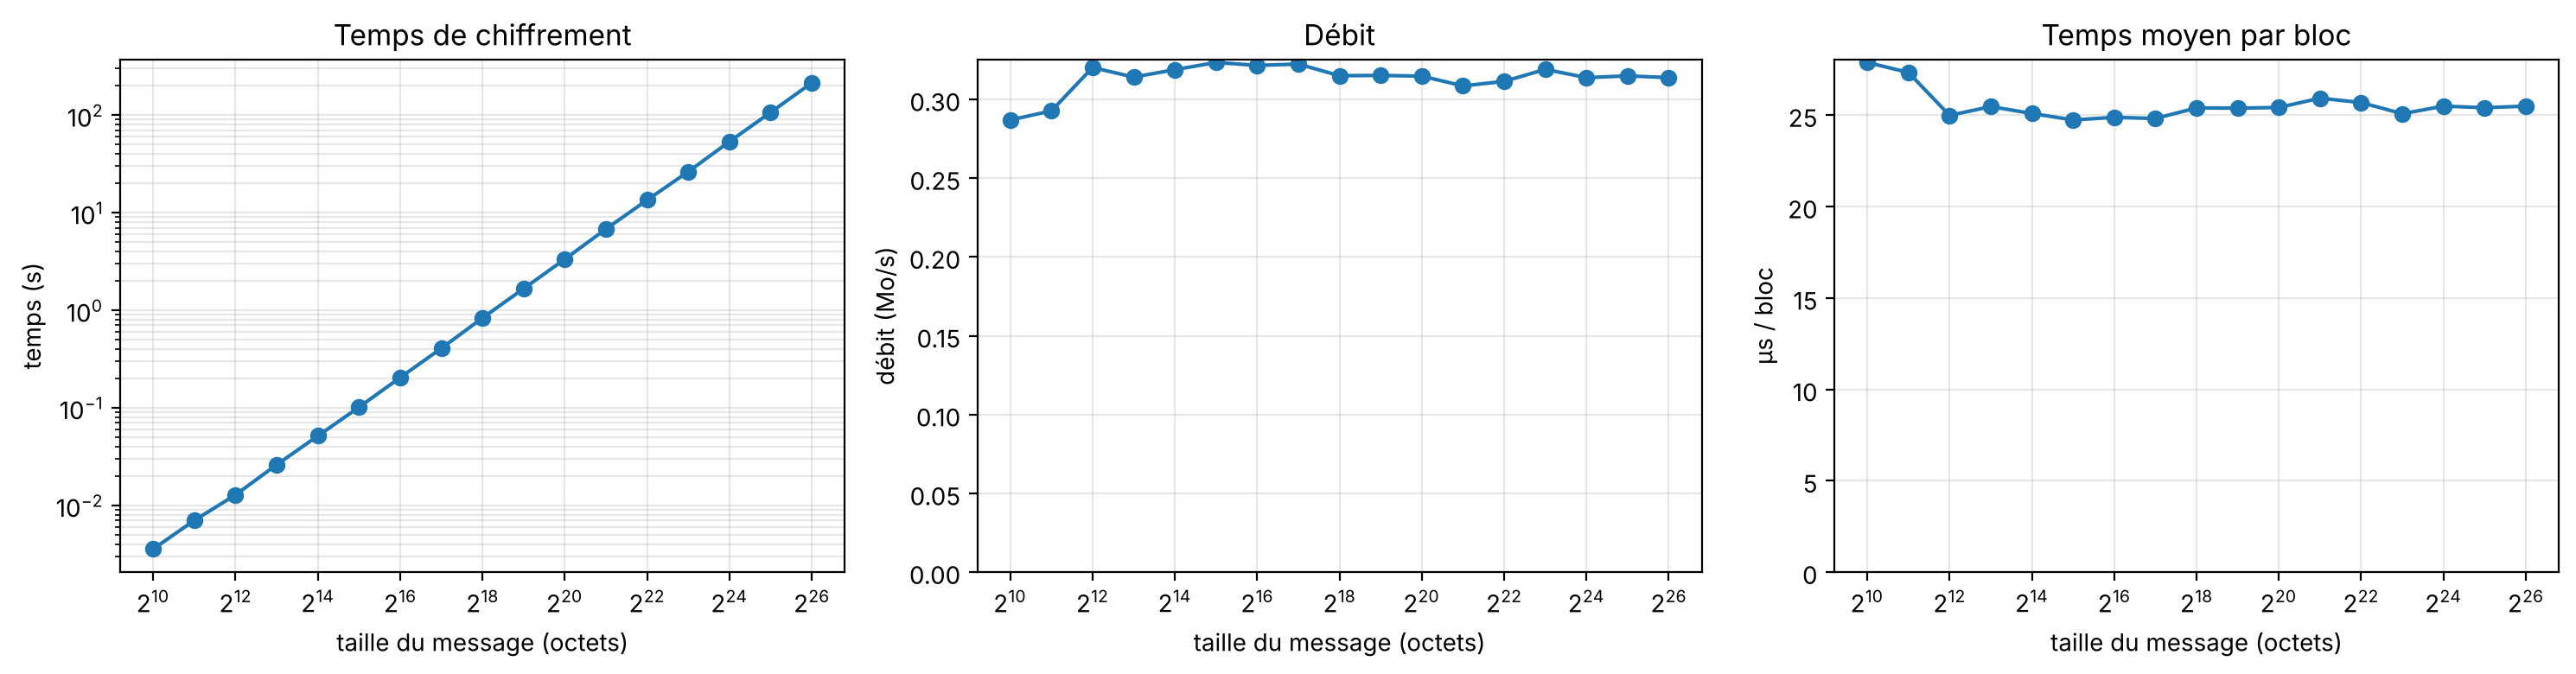

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].loglog(df["taille (o)"], df["t_nous (s)"], "o-")
ax[0].set_xscale("log", base=2)
ax[0].set_xlabel("taille du message (octets)"); ax[0].set_ylabel("temps (s)")
ax[0].set_title("Temps de chiffrement"); ax[0].grid(True, which="both", alpha=.3)

ax[1].semilogx(df["taille (o)"], df["débit nous (Mo/s)"], "o-", base=2)
ax[1].set_xlabel("taille du message (octets)"); ax[1].set_ylabel("débit (Mo/s)")
ax[1].set_title("Débit"); ax[1].set_ylim(bottom=0); ax[1].grid(True, alpha=.3)

ax[2].semilogx(df["taille (o)"], df["µs/bloc nous"], "o-", base=2)
ax[2].set_xlabel("taille du message (octets)"); ax[2].set_ylabel("µs / bloc")
ax[2].set_title("Temps moyen par bloc"); ax[2].set_ylim(bottom=0); ax[2].grid(True, alpha=.3)

plt.tight_layout(); plt.show()

**Analyse :**
- Le temps de chiffrement est **linéaire** en la taille du message (droite de pente 1 en log-log) : c'est attendu car en ECB chaque bloc est chiffré indépendamment avec le même coût ($O(n)$).
- Le **temps par bloc** est donc constant (≈ 25 µs/bloc) et le **débit** aussi (≈ 0,31 Mo/s). Le premier point ($2^{10}$) est un peu plus lent (≈ 28 µs/bloc) à cause des coûts fixes (calcul des sous-clés, allocation). Il y a de petites variations dues au système (autres processus, cache, ramasse-miettes Python).
- Le calcul des sous-clés est fait une seule fois par message, son coût est négligeable même pour $2^{10}$ octets (128 blocs).
- Cette implémentation est limitée par l'interpréteur Python : chaque bloc demande quelques centaines d'opérations Python (lectures de tables, décalages, XOR) qui coûtent chacune des dizaines de ns.

## 5. Comparaison avec PyCryptodome

Tous les chiffrés identiques : True


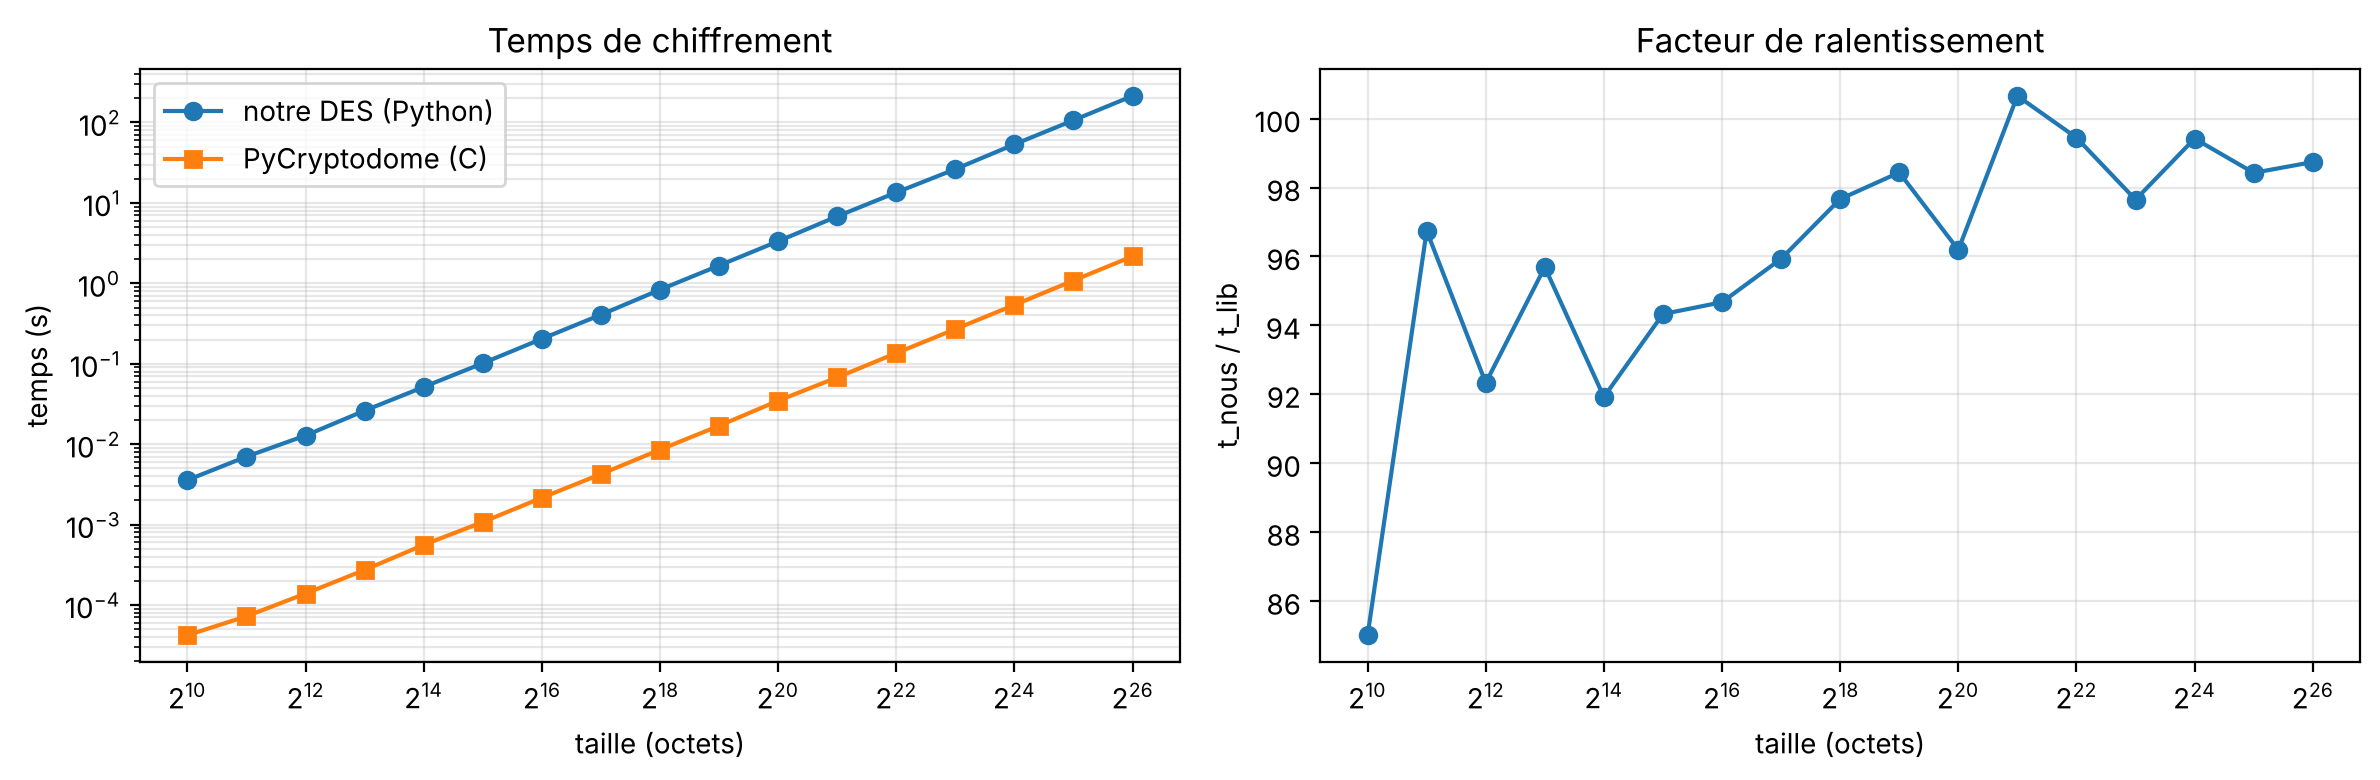

Débit moyen : nous 0.31 Mo/s, lib 30.1 Mo/s


In [6]:
print("Tous les chiffrés identiques :", df["identique"].all())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(df["taille (o)"], df["t_nous (s)"], "o-", label="notre DES (Python)")
ax[0].loglog(df["taille (o)"], df["t_lib (s)"], "s-", label="PyCryptodome (C)")
ax[0].set_xscale("log", base=2)
ax[0].set_xlabel("taille (octets)"); ax[0].set_ylabel("temps (s)")
ax[0].legend(); ax[0].grid(True, which="both", alpha=.3); ax[0].set_title("Temps de chiffrement")

ax[1].semilogx(df["taille (o)"], df["rapport"], "o-", base=2)
ax[1].set_xlabel("taille (octets)"); ax[1].set_ylabel("t_nous / t_lib")
ax[1].set_title("Facteur de ralentissement"); ax[1].grid(True, alpha=.3)
plt.tight_layout(); plt.show()

print(f"Débit moyen : nous {df['débit nous (Mo/s)'].mean():.2f} Mo/s, "
      f"lib {df['débit lib (Mo/s)'].mean():.1f} Mo/s")

**Analyse :**
- Les deux implémentations donnent **exactement le même chiffré** pour toutes les tailles, ce qui confirme que notre DES est conforme à la norme.
- PyCryptodome est **environ 100 fois plus rapide** (~30 Mo/s contre ~0,31 Mo/s). Les raisons :
  - elle est écrite en **C** et compilée : une opération sur des bits coûte ~1 cycle, contre des dizaines de ns par opération dans l'interpréteur Python (et nos entiers Python sont des objets alloués dynamiquement) ;
  - toute la boucle sur les blocs est faite en C, on ne fait qu'un seul appel depuis Python ;
  - elle utilise des tables optimisées (S-box et P combinées en « SP-boxes » de 32 bits), ce qui réduit encore le nombre d'opérations par tour.
- Pour les petites tailles ($2^{10}$), le rapport est un peu plus faible (≈ 85 au lieu de ≈ 98) car le coût fixe de la bibliothèque (création de l'objet `DES.new`, appel Python→C) n'est pas négligeable devant le chiffrement de 128 blocs. Pour les grandes tailles, le rapport se stabilise.
- Notre optimisation par tables (notebook 02) nous fait déjà gagner un facteur ~4 par rapport à la version bit à bit, mais pour aller plus loin il faudrait passer en C/C++ ou utiliser des outils comme Cython/Numba.